[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/protocols/agentic_mimicking_protocols/TraditionalML/2_Text_embeddings/Text_Embeddings_Protocol.ipynb)

# EduAll Foundation — Grant Call 2026
## Group Project Report: Traditional Machine Learning — Text Embeddings of the Application Statements

**Protocol:** `protocols/humaAI_Machine_Learning.pdf` — Human-AI condition, Approach 1 of 3 (traditional ML).
**Modeling path chosen:** example 2 of the protocol, *Text embeddings → similarity to call priorities → clustering*.
**Group:** Group ML-2, four students (A, B, C, D).
**Input data:** `data/EduAll_500_Applications_Dataset.csv` and the 500 application files in
`data/individual_applications/`.

We turn each applicant's written statements into vectors (TF-IDF, then a sentence-transformer model), measure how closely each text matches the call's priority wording, cluster the texts, and check what the text signal actually captures before deciding how much weight it gets in the funding list.

This notebook **is** our project report. It follows the protocol's four steps:

1. **Anchor the model's objective** — from the mission statement and the grant call: the 7 eligibility
   (hard, pass/fail) and 5 priority (soft, scored) criteria, plus the nuances we add as a group.
2. **Choose and execute a modeling path** — and why we chose it.
3. **Build and validate** — features used and excluded, fitting, the validation criterion, seed-sensitivity
   runs, and a human review of the model's output against the underlying records.
4. **Documentation and reproducibility** — full specification, which decisions are the model's and which
   are ours, the final funding list, and the output files `decision_progression.csv` and
   `final_allocation.csv`.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "protocols/agentic_mimicking_protocols/TraditionalML/2_Text_embeddings"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

---
## Step 1 — Anchor the model's objective

*Budget: ~13.0h for a 4-student group.*

We read the foundation's **Organization Profile** (mission and values) and the **Grant Call 2026**
(eligibility, ineligible categories, priority considerations, weighted evaluation criteria, award rules),
and the FAQ where the call refers to it.

**Mission (Organization Profile):** *"Our focus is not on academic excellence or competition, but rather on
identifying students with genuine financial need and providing them with the means to pursue their
studies."*

### 1.1 Eligibility criteria (hard, pass/fail, n = 7)

These are the call's seven *Primary Eligibility Requirements*. The last column says how we check each one in
the data, including our group's decisions where the call leaves room for interpretation.

| # | Criterion (Grant Call) | How we check it | Our decision |
|---|---|---|---|
| H1 | Non-Swiss citizen | `country_origin` | All 500 applicants are international by construction: pass. |
| H2 | Legally residing in Switzerland (valid permit B, C, F, S...; pending permits case by case) | `residency_permit`, plus the ineligible category *"Permit C and significant family financial resources"* | Permits B, C, F, S pass; Pending permits are eligible and *conditional*. Permit C with a supporting household of CHF 7,000/month or more fails. Our threshold is higher than a median wage because the household often supports several people, and the call speaks of *significant* resources. |
| H3 | Accepted or enrolled at an accredited Swiss institution | `university` | All listed institutions are accredited: pass. |
| H4 | Documented genuine financial need | expected 2027/28 shortfall `monthly_expenses − family support − expected personal income`, for the months of study inside the grant period (Sep 2027 – Aug 2028) | Pass if the expected 2027/28 shortfall is positive for at least one month of study inside the grant period (completion date read from the application file). |
| H5 | Satisfactory academic standing, normally GPA ≥ 2.5 (exceptions if the reasons are explained) | `gpa`, `academic_standing`, and the written statements | GPA ≥ 2.5 passes. Below 2.5 the call allows an exception *if the reasons are explained*. Since our approach reads the texts, we check this: the applicant passes if the statements discuss grades, exams or an improvement plan (keyword check, Step 3); otherwise H5 fails. |
| H6 | Bachelor's, master's or doctoral degree, full-time or part-time | `study_level`, `study_mode` | All applicants qualify: pass. |
| H7 | No outstanding legal or immigration issues | not observable in the data | Assumed satisfied; pending permits are handled in H2. |


### 1.2 Priority criteria (soft, scored, n = 5)

| # | Criterion (Grant Call weight) | What it means for us | Variables |
|---|---|---|---|
| S1 | Financial need (40%) | Shortfall relative to expenses in 2027/28. In the statements: the hardship and the lack of alternatives, in the applicant's own words. | `shortfall_ratio`; Section 4 text |
| S2 | Academic motivation & potential (25%) | Clear goals and their coherence with the programme. This is mainly visible in the personal statement. | Section 5 text; `gpa` |
| S3 | Personal resilience & determination (20%) | Overcoming challenges, independence and engagement, as the applicant describes them. | Section 7 statement; Section 5 text |
| S4 | Contribution to diversity (10%) | Low-income country and first-generation status. | `gni_tier`, `risk_first_generation` |
| S5 | Alignment with EduAll values (5%) | Commitment to education as a right and to community. | Section 5 and 7 texts |

The call also names **priority groups**: students from low-income countries (GNI per capita below USD 3,000,
`gni_tier == 1`), first-generation students, students from under-represented regions, and students
demonstrating exceptional resilience.


### 1.3 Nuances we add as a group

* **The texts are the only place where the applicant explains their situation.** The call's criteria are written in
  qualitative terms ("demonstrated genuine hardship", "clear educational goals", "evidence of overcoming
  challenges"), and the CSV only has numbers and ticked boxes. We want to test whether a text model can bring that
  qualitative evidence into a reproducible ranking.
* **But writing skill is not a criterion.** Many applicants write in their second or third language. Before the text
  signal is allowed to affect awards, we check that it does not simply reward length, vocabulary or fluency.
* **Savings.** The call says savings are "taken into account". We count half of the declared savings against the
  grant-period request. The other half is assumed to cover the year before the grant starts (Sep 2026 – Aug 2027).

❓ **Question for students:** a text model rewards *how* applicants describe their situation. Under which conditions
would that be fair to applicants who write in a second language, or who are reluctant to describe personal hardship?

---
## Step 2 — Choose and execute a modeling path

*Budget: ~27.6h.*

We chose the protocol's **text-embeddings path** (unsupervised: there is no outcome to predict). Representations:

1. **TF-IDF** (word and two-word terms): transparent, since we can see which words drive a similarity;
2. **Sentence embeddings** with `all-MiniLM-L6-v2` (384 dimensions): captures meaning beyond shared words
   ("my parents cannot help me" ≈ "no family support").

**Reference.** A text built from the call's own evaluation wording (the bullet points under the five weighted criteria).
For each applicant: cosine similarity between their statements and this reference.
**Structure.** k-means on the embeddings, with *k* chosen by silhouette.

In [1]:
import importlib.util, subprocess, sys
_missing = [p for p, m in [("sentence-transformers", "sentence_transformers")] if importlib.util.find_spec(m) is None]
if _missing:                                   # e.g. on Google Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
import pathlib, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import logging, os
os.environ["TRANSFORMERS_VERBOSITY"] = "error"; os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
from sentence_transformers import SentenceTransformer
import transformers; transformers.logging.disable_progress_bar()
from scipy.stats import spearmanr
SEED = 2026
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
# Data: works from the course folder (protocols/agentic_mimicking_protocols/TraditionalML/<approach>/)
# and on Google Colab (upload the CSV and individual_applications.zip when asked).
CANDIDATES = [pathlib.Path("../../../../data"), pathlib.Path("../../../data"), pathlib.Path("data"), pathlib.Path(".")]
DATA = next((b for b in CANDIDATES if (b / "EduAll_500_Applications_Dataset.csv").exists()), None)
if DATA is None:
    from google.colab import files            # only reached on Colab
    print("Upload EduAll_500_Applications_Dataset.csv and individual_applications.zip")
    files.upload()
    DATA = pathlib.Path(".")
APPS = DATA / "individual_applications"
if not APPS.exists() and (DATA / "individual_applications.zip").exists():
    with zipfile.ZipFile(DATA / "individual_applications.zip") as z:
        z.extractall(DATA)

df = pd.read_csv(DATA / "EduAll_500_Applications_Dataset.csv", keep_default_na=False).set_index("student_id", drop=False)
df.index.name = None
docs = {sid: (APPS / f"{sid}_application.md").read_text(encoding="utf-8") for sid in df.student_id}
print(df.shape, "| application files:", len(docs))

(500, 44) | application files: 500


In [3]:
# Quantities every approach needs, computed from the call's own rules
RISK = ["risk_first_generation", "risk_refugee_asylum", "risk_disability", "risk_housing_insecurity",
        "risk_family_emergency", "risk_language_barrier", "risk_parent_student", "risk_undocumented_status"]
RESIL = ["resilience_volunteer_experience", "resilience_work_experience", "resilience_leadership_role",
         "resilience_community_engagement", "resilience_overcame_adversity"]
CAP = {"Bachelor's": 8000, "Master's": 6500, "Doctoral": 5000}          # annual maximum by level
REQUIRED = {"Bachelor's": 40, "Master's": 12, "Doctoral": 12}             # courses per degree

# Expected completion is stated in each application form; we read it from the file.
MONTH = {"January": 1, "July": 7}
def completion(text):
    m = re.search(r"\*\*Expected Completion:\*\*\s*(January|July) (\d{4})", text)
    return (int(m.group(2)), MONTH[m.group(1)]) if m else (None, None)

df["completion_year"], df["completion_month"] = zip(*[completion(docs[s]) for s in df.student_id])
# months of study inside the grant period Sep 2027 - Aug 2028 (finish Jan 2028 -> 5, Jul 2028 -> 11, later -> 12)
grant_end = (2028, 8)
def months_in_grant(y, m):
    if y is None: return 12
    if (y, m) < (2027, 9): return 0
    if (y, m) >= grant_end: return 12
    return (y - 2027) * 12 + m - 9 + 1
df["months_in_grant"] = [months_in_grant(y, m) for y, m in zip(df.completion_year, df.completion_month)]
df["months_to_completion"] = [(y - 2026) * 12 + m - 9 + 1 for y, m in zip(df.completion_year, df.completion_month)]  # from Sep 2026

df["need_2027"] = (df.monthly_expenses_chf - df.family_income_chf - df.expected_personal_income_2027_chf).clip(lower=0)
df["shortfall_ratio"] = (df.need_2027 / df.monthly_expenses_chf).clip(0, 1)
df["risk_count"] = df[RISK].sum(axis=1)
df["resil_count"] = df[RESIL].sum(axis=1)
df["progress"] = (df.courses_completed / df.study_level.map(REQUIRED)).clip(0, 1)
df["cap_period"] = df.study_level.map(CAP) * df.months_in_grant / 12
print(df.months_in_grant.value_counts().sort_index().to_dict())

{5: 50, 11: 283, 12: 167}


In [4]:

# H5 exception check from the text: does the applicant explain the grades / show improvement?
EXPLAIN = re.compile(r"\b(GPA|grades?|exam(s|ination)?|failed|retake|improv\w*|study plan|academic (difficult|problem)\w*)\b", re.I)
def statements(text):                       # the three written statements only
    parts = re.split(r"\n## ", text)
    keep = [p for p in parts if p.startswith(("Section 4", "Section 5", "Section 7"))]
    return "\n".join(keep)
df["explains_gpa"] = [bool(EXPLAIN.search(statements(docs[s]))) for s in df.student_id]

PERMIT_C_LIMIT = 7000      # "significant family financial resources" for Permit C (our threshold)
df["H1"] = np.where(df.country_origin != "Switzerland", "pass", "fail")
df["H2"] = np.select([(df.residency_permit == "C") & (df.family_household_income_chf >= PERMIT_C_LIMIT),
                      df.residency_permit == "Pending"],
                     ["fail (Permit C, household >= CHF 7,000)", "conditional (permit pending)"], "pass")
df["H3"] = np.where(df.university.str.len() > 0, "pass", "fail")
df["H4"] = np.where((df.need_2027 > 0) & (df.months_in_grant > 0), "pass", "fail (no shortfall in grant period)")
df["H5"] = np.where(df.gpa >= 2.5, "pass", np.where(df.explains_gpa, "pass (explained)", "fail"))
df["H6"] = np.where(df.study_level.isin(CAP) & df.study_mode.isin(["Full-time", "Part-time"]), "pass", "fail")
df["H7"] = "pass (assumed)"
HARD = ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]
df["eligible"] = ~df[HARD].apply(lambda c: c.str.startswith("fail")).any(axis=1)
df["conditional"] = df[HARD].apply(lambda c: c.str.startswith("conditional")).any(axis=1)
summary = pd.DataFrame({h: df[h].value_counts() for h in HARD}).fillna(0).astype(int)
display(summary)
print(f"eligible: {df.eligible.sum()} of {len(df)} (of which conditional: {(df.eligible & df.conditional).sum()})")

,H1,H2,H3,H4,H5,H6,H7
conditional (permit pending),0,16,0,0,0,0,0
fail,0,0,0,0,36,0,0
"fail (Permit C, household >= CHF 7,000)",0,18,0,0,0,0,0
fail (no shortfall in grant period),0,0,0,76,0,0,0
pass,500,466,500,424,419,500,0
pass (assumed),0,0,0,0,0,0,500
pass (explained),0,0,0,0,45,0,0


eligible: 386 of 500 (of which conditional: 16)


In [5]:
# Award request for the grant period: shortfall x months, minus other scholarships and savings, capped
# Savings: half of declared savings is counted against the grant period
df["scholarship_period"] = df.external_scholarship_amount_chf * df.months_in_grant / 12
df["savings_counted"] = (0.5 * df.savings_chf).round()
df["request"] = (df.need_2027 * df.months_in_grant - df.scholarship_period - df.savings_counted).clip(lower=0)
df["request"] = np.minimum(df.request, df.cap_period).round()
print(f"eligible applicants with a positive request: {(df.eligible & (df.request > 0)).sum()}; "
      f"their total request: CHF {df.loc[df.eligible, 'request'].sum():,.0f} vs budget CHF 500,000")

eligible applicants with a positive request: 362; their total request: CHF 1,973,206 vs budget CHF 500,000


---
## Step 3 — Build and validate

*Budget: ~81.2h.*

### 3.1 Text preparation

**Used:** the free text of Section 4 (financial need statement), Section 5 (personal statement) and the *Statement of
Declared Circumstances* in Section 7.
**Excluded:** the form's instruction lines (identical for everyone), the tick-box lists (already in the CSV),
Sections 1–3 (structured data), Section 6 (CV summary: lists, not statements) and the references.
Structured variables such as gender, age, country, university and field are not used to build the text signal.
They only appear in the review in 3.5.

In [6]:
def free_text(t):
    out = []
    for part in re.split(r"\n## ", t):
        if part.startswith(("Section 4", "Section 5")):
            body = part.split("\n", 1)[1]
        elif part.startswith("Section 7") and "### Statement of Declared Circumstances" in part:
            body = part.split("### Statement of Declared Circumstances", 1)[1]
        else:
            continue
        body = re.sub(r"^\*Instructions:.*$", "", body, flags=re.M).replace("---", "")
        out.append(body.strip())
    return "\n\n".join(out)

df["text"] = [free_text(docs[s]) for s in df.student_id]
df["words"] = df.text.str.split().str.len()
print(df.words.describe().round(0).to_dict())
print("\nExample (first 600 characters):\n", df.text.iloc[0][:600])

{'count': 500.0, 'mean': 417.0, 'std': 121.0, 'min': 158.0, '25%': 335.0, '50%': 401.0, '75%': 487.0, 'max': 993.0}

Example (first 600 characters):
 On paper my monthly budget balances, and I want to be honest about that. My parents send me CHF 220 a month and I earn CHF 816 from my job as a student assistant at the university library, where I work around seven hours a week. My expenses come to CHF 1,745, so in a normal month I have a small margin left.

The problem is that my situation is not stable, and I have no savings at all to absorb any shock. Since I arrived in Geneva I have moved four times. I have always lived in sublets because I could not get a regular lease without a Swiss guarantor or a deposit. My current room costs CHF 704 


### 3.2 The reference text (stated in full)

Variant **R1** is the call's evaluation wording. We also write two variants, so that we can check how much the
ranking depends on our wording (Step 3.4): **R2** is the same content in first person, as an applicant would write it;
**R3** covers financial need only.

In [7]:
REF = {
 "R1_call_wording": ("Demonstrated genuine financial hardship. Lack of alternative funding sources. High living costs compared "
     "to available resources. Low-income country or disadvantaged socioeconomic background. Clear educational goals. Academic "
     "progress and commitment to studies. Coherence between aspirations and study program. Evidence of overcoming challenges. "
     "Self-motivation and independence. Community engagement or volunteer work. Personal growth. First-generation university "
     "student. Commitment to education as a right and to giving back to the community."),
 "R2_first_person": ("My family cannot support me and I have no other scholarship or savings; every month my costs are higher "
     "than what I earn. I come from a poor country and I am the first in my family to go to university. I know exactly what I "
     "want to study and why, and I work hard to finish my degree. I have overcome serious difficulties, I work, I volunteer "
     "and I want to give back to my community."),
 "R3_need_only": ("I cannot pay my rent, food and tuition. My family has no money to help me, I have no savings, no other "
     "scholarship, and my job does not cover my costs. Without support I will have to stop my studies."),
}

### 3.3 TF-IDF and sentence-embedding similarity

The model has a 256-token input limit, and the three statements together run to 158–993 words per applicant (median about 400, Step 3.1). We therefore embed each
**paragraph** separately and average the paragraph vectors per applicant. This is our own choice; truncating the text
would discard most of each statement.

In [8]:
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.8, sublinear_tf=True)
T = tfidf.fit_transform(df.text)
Tref = tfidf.transform(list(REF.values()))
sim_tfidf = pd.DataFrame((T @ Tref.T).toarray(), index=df.index, columns=REF.keys()).astype(float)
print("TF-IDF vocabulary:", T.shape[1], "terms")

st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
paras = [(sid, p) for sid, t in zip(df.student_id, df.text) for p in re.split(r"\n\s*\n", t) if len(p) > 40]
P = st.encode([p for _, p in paras], batch_size=64, normalize_embeddings=True, show_progress_bar=False)
owner = pd.Series([sid for sid, _ in paras])
Emb = np.vstack([P[(owner == sid).values].mean(axis=0) for sid in df.student_id])
Emb /= np.linalg.norm(Emb, axis=1, keepdims=True)
Eref = st.encode(list(REF.values()), normalize_embeddings=True)
sim_st = pd.DataFrame(Emb @ Eref.T, index=df.index, columns=REF.keys()).astype(float)
print("paragraphs embedded:", len(paras), "| embedding matrix:", Emb.shape)
df["text_sim"] = sim_st["R1_call_wording"]
df["text_sim_tfidf"] = sim_tfidf["R1_call_wording"]
sim_st.describe().round(3)

TF-IDF vocabulary: 8363 terms


paragraphs embedded: 6417 | embedding matrix: (500, 384)


,R1_call_wording,R2_first_person,R3_need_only
count,500.000,500.000,500.000
mean,0.452,0.424,0.331
std,0.066,0.071,0.069
min,0.256,0.153,0.127
25%,0.404,0.375,0.283
50%,0.455,0.430,0.333
75%,0.504,0.473,0.377
max,0.599,0.633,0.546


### 3.4 Validation without labels: agreement, wording sensitivity, cluster structure and seeds

There is no "true" ranking to compare with. We check instead (a) whether two very different representations agree on
the ranking, (b) whether the ranking survives a change in the wording of our reference, and (c) whether the
text clusters are real and stable.

In [9]:
elig = df.eligible
print("Spearman, TF-IDF vs sentence-embedding ranking (R1, eligible):",
      round(spearmanr(sim_tfidf.loc[elig, "R1_call_wording"], sim_st.loc[elig, "R1_call_wording"])[0], 3))
print("\nSpearman between reference wordings (sentence embeddings, eligible):")
display(sim_st[elig].corr(method="spearman").round(3))
top = lambda s: set(s[elig].nlargest(150).index)
print("overlap of the top-150 lists, R1 vs R2:", len(top(sim_st.R1_call_wording) & top(sim_st.R2_first_person)),
      "| R1 vs R3:", len(top(sim_st.R1_call_wording) & top(sim_st.R3_need_only)))

Spearman, TF-IDF vs sentence-embedding ranking (R1, eligible): 0.325

Spearman between reference wordings (sentence embeddings, eligible):


,R1_call_wording,R2_first_person,R3_need_only
R1_call_wording,1.000,0.650,0.548
R2_first_person,0.650,1.000,0.895
R3_need_only,0.548,0.895,1.000


overlap of the top-150 lists, R1 vs R2: 102 | R1 vs R3: 95


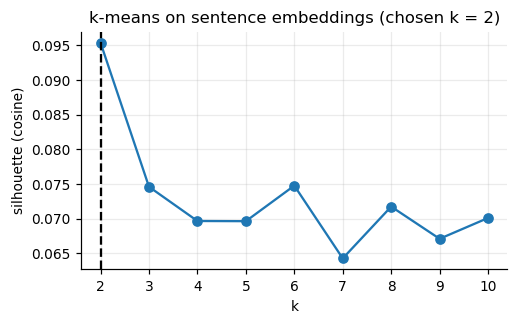

{2: 0.095, 3: 0.075, 4: 0.07, 5: 0.07, 6: 0.075, 7: 0.064, 8: 0.072, 9: 0.067, 10: 0.07}
seed sensitivity: ARI between 5 seeds, min 0.90, mean 0.94


,n,text_sim,shortfall_ratio,tier1 %,doctoral %,part-time %,distinctive terms
cluster,,,,,,,
0,132,0.42,0.45,50.00,14.39,23.48,"hospital, medicine, nursing, care, medical, doctor, health, nurse, patients, care assistant"
1,368,0.46,0.55,49.73,8.97,28.80,"physics, school, mathematics, history, science, engineering, parents went, schools, left, housing"


Cramer's V (text cluster vs field_of_study): 0.76
Cramer's V (text cluster vs gender): 0.06
Cramer's V (text cluster vs geographic_region): 0.11
cluster 0, most frequent fields: {'Medicine': 23, 'Microbiology': 21, 'Nursing': 19, 'Public Health': 16}
cluster 1, most frequent fields: {'Physics': 45, 'Materials Science': 23, 'Education': 23, 'Computer Science': 21}


In [10]:
sil = {k: silhouette_score(Emb, KMeans(k, n_init=10, random_state=SEED).fit_predict(Emb), metric="cosine") for k in range(2, 11)}
K = max(sil, key=sil.get)
plt.figure(figsize=(5, 2.8)); plt.plot(list(sil), list(sil.values()), "o-"); plt.axvline(K, ls="--", c="k")
plt.xlabel("k"); plt.ylabel("silhouette (cosine)"); plt.title(f"k-means on sentence embeddings (chosen k = {K})"); plt.show()
df["text_cluster"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(Emb)
labs = {s: KMeans(K, n_init=10, random_state=s).fit_predict(Emb) for s in [1, 7, 42, 2026, 31415]}
ari = [adjusted_rand_score(labs[a], labs[b]) for i, a in enumerate(labs) for b in list(labs)[i + 1:]]
print({k: round(v, 3) for k, v in sil.items()})
print(f"seed sensitivity: ARI between 5 seeds, min {min(ari):.2f}, mean {np.mean(ari):.2f}")

terms = np.array(tfidf.get_feature_names_out())
Td = T.toarray(); overall = Td.mean(axis=0)
rows = []
for c in range(K):
    m = (df.text_cluster == c).values
    lift = Td[m].mean(axis=0) - overall
    rows.append({"cluster": c, "n": m.sum(), "text_sim": df.text_sim[m].mean(), "shortfall_ratio": df.shortfall_ratio[m].median(),
                 "tier1 %": (df.gni_tier[m] == 1).mean() * 100, "doctoral %": (df.study_level[m] == "Doctoral").mean() * 100,
                 "part-time %": (df.study_mode[m] == "Part-time").mean() * 100,
                 "distinctive terms": ", ".join(terms[np.argsort(lift)[::-1][:10]])})
clusters = pd.DataFrame(rows).set_index("cluster").round(2)
with pd.option_context("display.max_colwidth", 120):
    display(clusters)
from scipy.stats import chi2_contingency
for col in ["field_of_study", "gender", "geographic_region"]:
    t = pd.crosstab(df.text_cluster, df[col]).values
    print(f"Cramer's V (text cluster vs {col}): {np.sqrt(chi2_contingency(t)[0] / (t.sum() * (min(t.shape) - 1))):.2f}")
for c in range(K):
    print(f"cluster {c}, most frequent fields:", df.loc[df.text_cluster == c, "field_of_study"].value_counts().head(4).to_dict())

**What we see (all four of us).**

* **The two representations disagree.** The Spearman correlation between the TF-IDF and the sentence-embedding rankings is only 0.33. TF-IDF rewards *shared words* with the call's text. The embeddings reward *similar meaning*. The two do not produce the same ranking, so the choice of representation is itself a consequential decision.
* **The wording of the reference matters.** Changing our reference from the call's wording (R1) to a first-person paraphrase (R2) gives a Spearman correlation of 0.65, and only 102 of the top-150 applicants stay the same. The need-only text (R3) shares 95 of the top 150 with R1. R2 and R3 are close to each other (0.90): both are written in the first person, like the statements. The *style* of the reference therefore shifts the ranking about as much as its *content*.
* **The clusters are about the field of study, not about need.** The silhouette is low for every k (0.06 to 0.10) and highest at k = 2. The two clusters are perfectly stable across seeds (ARI ≥ 0.90), but they separate health and care programmes (Medicine, Microbiology, Nursing, Public Health: terms *hospital, care, patients*) from everything else. Cramér's V with field of study is **0.76**. The text structure is mostly **what people study**: an unintended proxy, exactly what the protocol warns about. We do not use the clusters for funding.

❓ **Question for students:** our reference text R1 was written by us from the call's bullet points, and a small change in its wording reorders a third of the top-150 list. Who should write the reference text in a real selection process, and should applicants be told what it says?

### 3.5 Human review: what does the text similarity actually measure?

Before giving the text signal any weight, we check (a) its correlation with the structured need variables and with
features it should *not* depend on (length, field, gender), and (b) the statements of the three highest- and the three
lowest-scoring eligible applicants, read in full by two of us each.

,Spearman with text_sim (eligible)
shortfall_ratio,0.05
need_2027,0.03
family_household_income_chf,-0.02
gni_tier,-0.14
risk_count,0.25
resil_count,0.33
gpa,-0.03
words,0.24


mean text_sim by gender: {'Female': 0.457, 'Male': 0.453, 'Non-binary': 0.472, 'Prefer not to say': 0.465}
mean text_sim by study level: {"Bachelor's": 0.462, 'Doctoral': 0.453, "Master's": 0.451}


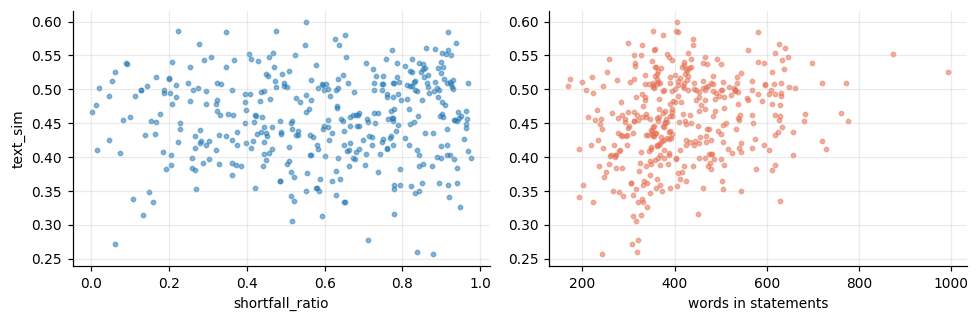

In [11]:
E = df[df.eligible]
def rho(col):
    return spearmanr(E.text_sim, pd.factorize(E[col])[0] if E[col].dtype == object else E[col])[0]
checks = ["shortfall_ratio", "need_2027", "family_household_income_chf", "gni_tier", "risk_count", "resil_count", "gpa", "words"]
display(pd.Series({c: rho(c) for c in checks}, name="Spearman with text_sim (eligible)").round(2).to_frame())
print("mean text_sim by gender:", E.groupby("gender").text_sim.mean().round(3).to_dict())
print("mean text_sim by study level:", E.groupby("study_level").text_sim.mean().round(3).to_dict())
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].scatter(E.shortfall_ratio, E.text_sim, s=8, alpha=.5); axs[0].set_xlabel("shortfall_ratio"); axs[0].set_ylabel("text_sim")
axs[1].scatter(E.words, E.text_sim, s=8, alpha=.5, c="#e76f51"); axs[1].set_xlabel("words in statements")
plt.tight_layout(); plt.show()

In [12]:
def show(sid, n=700):
    r = df.loc[sid]
    print(f"{sid} | text_sim {r.text_sim:.3f} | {r.study_level}, tier {r.gni_tier}, GPA {r.gpa} | shortfall ratio "
          f"{r.shortfall_ratio:.2f}, household CHF {r.family_household_income_chf:,}, savings CHF {r.savings_chf:,} | {r.words} words")
    print("   ", re.sub(r"\s+", " ", r.text)[:n], "...\n")
print("=== highest text similarity (eligible) ===")
for sid in E.text_sim.nlargest(3).index: show(sid)
print("=== lowest text similarity (eligible) ===")
for sid in E.text_sim.nsmallest(3).index: show(sid)

=== highest text similarity (eligible) ===
STU000317 | text_sim 0.599 | Bachelor's, tier 1, GPA 2.08 | shortfall ratio 0.55, household CHF 1,090, savings CHF 0 | 405 words
    I would like to be transparent about every aspect of my application, including the weakest one. I began the Bachelor's in Physics at the University of Geneva in September 2025. My monthly costs are CHF 2,222, mostly my room at CHF 1,145. I work as a kitchen assistant six hours a week and earn CHF 687. My mother, a shea butter trader in Tamale, gives me CHF 310, a large share of the roughly CHF 1,090 the household has. The gap is CHF 1,225 a month. My academic record in the first year is poor: my GPA is 2.08, and I am at risk. The move from Ghana to Geneva, the French language and the pace of the physics courses overwhelmed me, and I failed two courses. I am retaking them this autumn, and I h ...

STU000417 | text_sim 0.587 | Bachelor's, tier 2, GPA 2.64 | shortfall ratio 0.22, household CHF 5,200, savings CHF 0 |

**What the text similarity measures.** It is almost **uncorrelated with financial need**: Spearman 0.05 with the shortfall ratio, −0.02 with household income. It correlates with the declared resilience (0.33) and risk factors (0.25), and also with **length** (0.24 with the word count). Differences between genders and study levels are small (0.45–0.47).

**Reading the extremes (A and B read the top three, C and D the bottom three):**

* Highest: **STU000317** explains a GPA of 2.08 and an improvement plan in exactly the call's vocabulary. **STU000417** writes, carefully and honestly, that their money is enough today and that others may need it more (shortfall ratio 0.22). Both texts are excellent *answers to the call*, but only one of them describes high need.
* Lowest: **STU000477** writes in note style ("Gap: CHF 1,669 per month. … EduAll support = finish on time."), with a shortfall ratio of **0.88**. **STU000277** has lupus, cannot hold a student job, and has a shortfall ratio of **0.84**, but uses plainer language. **STU000267** has a gap of only CHF 108 per month; here the low score matches.

Two of the three lowest-scoring applicants are among the neediest in the pool. They score low because of their writing style, not their situation. The text signal on its own would penalise concise or plain writers, which conflicts with the call's equal-opportunity commitment.

---
## Step 4 — Documentation, and from model output to a funding list

*Budget: ~40.6h.*

### 4.1 Draft 1: fund by text similarity alone

The first version follows the approach literally. Eligible applicants are ranked by the similarity of their statements
to the call's wording (R1), and each receives 60% of their request (minimum CHF 1,500) until the budget is spent.

In [13]:
# Translate the model's ranking into a funding list (a HUMAN decision, see Step 4)
# DRAFT 1: text similarity only; 60% of request; minimum CHF 1,500
BUDGET, FRACTION, MIN_AWARD = 500_000, 0.6, 1500
order = df[df.eligible & (df.request > 0)].sort_values("text_sim", ascending=False).index
award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in order:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD:
        continue
    give = min(amt, left)
    if give < MIN_AWARD:
        break
    award[sid] = give
    left -= give
df["award"] = award
df["funding_rank"] = pd.Series(range(1, len(order) + 1), index=order).reindex(df.index)
print(f"funded: {(df.award > 0).sum()} applicants | awarded CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} "
      f"| mean award CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")

funded: 143 applicants | awarded CHF 498,502 | left CHF 1,498 | mean award CHF 3,486


In [14]:
df["award_draft1"] = df.award
f = df.award > 0
print("draft 1 | median shortfall ratio funded: %.2f vs eligible not funded: %.2f" % (
      df.loc[f, "shortfall_ratio"].median(), df.loc[df.eligible & ~f, "shortfall_ratio"].median()))
print("draft 1 | funded with shortfall ratio below 0.30:", (f & (df.shortfall_ratio < 0.3)).sum(),
      "| eligible with shortfall ratio above 0.80 NOT funded:", (df.eligible & ~f & (df.shortfall_ratio > 0.8)).sum())

draft 1 | median shortfall ratio funded: 0.72 vs eligible not funded: 0.58
draft 1 | funded with shortfall ratio below 0.30: 14 | eligible with shortfall ratio above 0.80 NOT funded: 48


**Draft 1 (text only): 143 awards, CHF 498,502.** The median shortfall ratio of recipients (0.72) is barely above that of eligible applicants not funded (0.58). 14 recipients have a shortfall ratio below 0.30, while **48 eligible applicants with a shortfall ratio above 0.80 receive nothing**. A list driven by text similarity alone does not satisfy the call's top criterion (financial need, 40%).

**Group decision (unanimous).** Text similarity becomes a *supporting* signal. Need, measured as the shortfall ratio from the structured data, leads. We give text 40%, because it is our only evidence for the qualitative parts of S2, S3 and S5, which together weigh 50% in the call. It does not get more, because of the style bias found in 3.5.

❓ **Question for students:** we chose 60/40 by argument, not by any model. If you wanted to set this weight more systematically, what could you validate it against, given that there is no ground truth?

### 4.2 Revision: text as a supporting signal

$$\text{priority} = 0.6\cdot\text{pct}(\text{shortfall\_ratio}) + 0.4\cdot\text{pct}(\text{text\_sim})$$

with percentiles taken among eligible applicants. Same award rule (60% of request, minimum CHF 1,500).

In [15]:
pctE = lambda s: s.where(df.eligible).rank(pct=True)
df["priority"] = 0.6 * pctE(df.shortfall_ratio) + 0.4 * pctE(df.text_sim)

In [16]:
# Translate the model's ranking into a funding list (a HUMAN decision, see Step 4)
# FINAL: 0.6 pct(shortfall ratio) + 0.4 pct(text similarity); 60% of request; minimum CHF 1,500
BUDGET, FRACTION, MIN_AWARD = 500_000, 0.6, 1500
order = df[df.eligible & (df.request > 0)].sort_values("priority", ascending=False).index
award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in order:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD:
        continue
    give = min(amt, left)
    if give < MIN_AWARD:
        break
    award[sid] = give
    left -= give
df["award"] = award
df["funding_rank"] = pd.Series(range(1, len(order) + 1), index=order).reindex(df.index)
print(f"funded: {(df.award > 0).sum()} applicants | awarded CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} "
      f"| mean award CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")

funded: 140 applicants | awarded CHF 500,000 | left CHF 0 | mean award CHF 3,571


In [17]:
moved_in = ((df.award > 0) & (df.award_draft1 == 0)).sum(); moved_out = ((df.award == 0) & (df.award_draft1 > 0)).sum()
print(f"compared with draft 1: {moved_in} applicants enter the list, {moved_out} leave it")

compared with draft 1: 47 applicants enter the list, 50 leave it


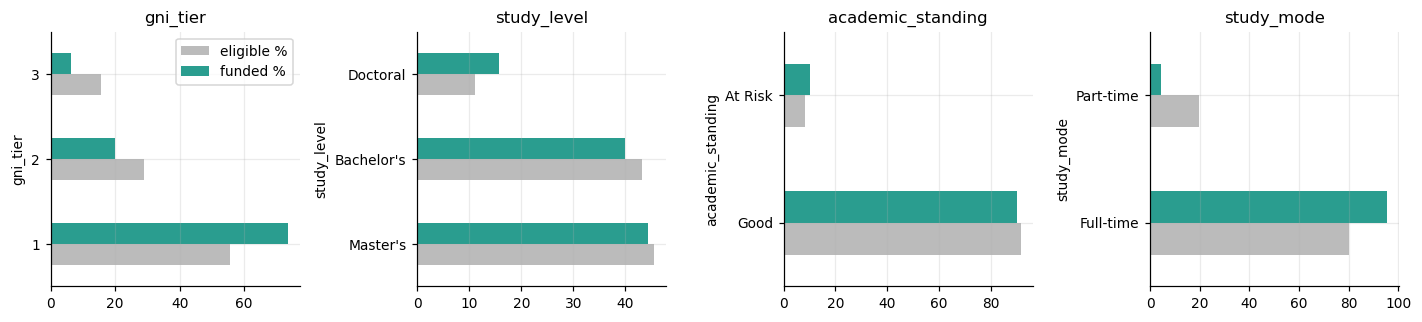

median shortfall ratio  funded: 0.84 | eligible not funded: 0.46


In [18]:
# Who is funded? Composition of the final list against the eligible pool
def share(col):
    e = df.loc[df.eligible, col].astype(str).value_counts(normalize=True).mul(100)
    f = df.loc[df.award > 0, col].astype(str).value_counts(normalize=True).mul(100)
    return pd.DataFrame({"eligible %": e, "funded %": f}).fillna(0).round(1)
fig, axs = plt.subplots(1, 4, figsize=(13, 3))
for ax, col in zip(axs, ["gni_tier", "study_level", "academic_standing", "study_mode"]):
    share(col).plot.barh(ax=ax, color=["#bbbbbb", "#2a9d8f"], legend=(col == "gni_tier"))
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("median shortfall ratio  funded: %.2f | eligible not funded: %.2f" % (
    df.loc[df.award > 0, "shortfall_ratio"].median(), df.loc[df.eligible & (df.award == 0), "shortfall_ratio"].median()))

**Final list: 140 awards, CHF 500,000** (mean CHF 3,571, i.e. 60% of each request). Compared with draft 1, 47 applicants enter and 50 leave. The median shortfall ratio is now **0.84** for recipients against 0.46 for eligible applicants not funded. Recipients by GNI tier: 103 tier 1, 28 tier 2, 9 tier 3. Eight recipients hold conditional awards (pending permits), and 14 recipients passed H5 on the strength of their explanation.

The text still matters at the margin: among applicants with similar need, the one whose statement discusses hardship, goals and resilience in terms close to the call's ranks higher. This is what we intended. The style bias found in 3.5 survives in a weaker form.

In [19]:
# Output files: the full decision path (all 500) and the final allocation (funded only)
df["status"] = np.select([df.award > 0, ~df.eligible], [np.where(df.conditional, "funded (conditional)", "funded"),
                         "not eligible"], "eligible, not funded")
df["reason"] = np.select([df.award > 0, ~df.eligible], ["rank " + df.funding_rank.astype("Int64").astype(str) + " by 0.6 need + 0.4 text; 60% of request", "failed: " + df[HARD].apply(lambda r: ", ".join(h for h in HARD if r[h].startswith("fail")), axis=1)], "eligible; budget exhausted before this rank")
INPUTS = ["student_id", "study_level", "study_mode", "residency_permit", "gni_tier", "geographic_region", "gpa",
          "academic_standing", "need_2027", "shortfall_ratio", "family_household_income_chf", "savings_chf",
          "external_scholarship_amount_chf", "risk_count", "resil_count", "completion_year", "completion_month",
          "months_in_grant"]
STEPS = HARD + ["eligible", "conditional"] + ["words", "text_sim", "text_sim_tfidf", "text_cluster", "award_draft1", "priority"] + ["request", "funding_rank", "award", "status", "reason"]
decision_progression = df[INPUTS + STEPS]
decision_progression.to_csv("decision_progression.csv", index=False)
final = decision_progression[decision_progression.award > 0].sort_values("funding_rank")
final.to_csv("final_allocation.csv", index=False)
print("decision_progression.csv:", decision_progression.shape, "| final_allocation.csv:", final.shape,
      f"| total CHF {final.award.sum():,.0f}")
final.head(8)

decision_progression.csv: (500, 38) | final_allocation.csv: (140, 38) | total CHF 500,000


,student_id,study_level,study_mode,residency_permit,gni_tier,geographic_region,gpa,academic_standing,need_2027,shortfall_ratio,family_household_income_chf,savings_chf,external_scholarship_amount_chf,risk_count,resil_count,...,H6,H7,eligible,conditional,words,text_sim,text_sim_tfidf,text_cluster,award_draft1,priority,request,funding_rank,award,status,reason
STU000274,STU000274,Bachelor's,Full-time,Pending,1,Sub-Saharan Africa,3.13,Good,1960,0.937799,540,2375,5151,4,3,...,pass,pass (assumed),True,True,299,0.568149,0.025785,1,4399.0,0.969430,7333.0,1.0,4399.0,funded (conditional),rank 1 by 0.6 need + 0.4 text; 60% of request
STU000238,STU000238,Bachelor's,Full-time,B,1,Sub-Saharan Africa,2.66,Good,1678,0.917943,910,11214,0,1,3,...,pass,pass (assumed),True,False,407,0.585001,0.025158,1,4399.0,0.953368,7333.0,2.0,4399.0,funded,rank 2 by 0.6 need + 0.4 text; 60% of request
STU000324,STU000324,Bachelor's,Full-time,B,1,Sub-Saharan Africa,4.00,Good,1747,0.925808,850,13340,0,1,3,...,pass,pass (assumed),True,False,328,0.551048,0.017731,0,4399.0,0.945078,7333.0,3.0,4399.0,funded,rank 3 by 0.6 need + 0.4 text; 60% of request
STU000048,STU000048,Bachelor's,Full-time,B,1,Sub-Saharan Africa,2.20,At Risk,1883,0.917194,1130,0,2131,2,0,...,pass,pass (assumed),True,False,559,0.557788,0.030795,1,4399.0,0.940415,7333.0,4.0,4399.0,funded,rank 4 by 0.6 need + 0.4 text; 60% of request
STU000356,STU000356,Master's,Full-time,B,1,Sub-Saharan Africa,3.38,Good,1993,0.912964,660,11869,1004,0,4,...,pass,pass (assumed),True,False,384,0.552376,0.028241,1,1624.0,0.928497,2708.0,5.0,1624.0,funded,rank 5 by 0.6 need + 0.4 text; 60% of request
STU000072,STU000072,Master's,Full-time,Pending,1,South Asia,3.37,Good,1567,0.902130,800,0,7872,3,3,...,pass,pass (assumed),True,True,617,0.553928,0.039798,1,3574.0,0.923834,5958.0,6.0,3574.0,funded (conditional),rank 6 by 0.6 need + 0.4 text; 60% of request
STU000198,STU000198,Doctoral,Full-time,B,1,South Asia,3.67,Good,2116,0.967978,430,14388,0,1,3,...,pass,pass (assumed),True,False,421,0.508667,0.034230,1,2749.0,0.910363,4583.0,7.0,2749.0,funded,rank 7 by 0.6 need + 0.4 text; 60% of request
STU000366,STU000366,Bachelor's,Full-time,B,1,Sub-Saharan Africa,2.74,Good,1931,0.884158,890,0,7267,2,4,...,pass,pass (assumed),True,False,358,0.559174,0.013095,1,4399.0,0.905181,7333.0,8.0,4399.0,funded,rank 8 by 0.6 need + 0.4 text; 60% of request


### 4.3 Which decisions are the model's, and which are ours

| Decision | Made by | How |
|---|---|---|
| Which parts of the application are read | Humans (us) | Sections 4, 5 and the Section 7 statement (3.1) |
| What the texts are compared with (the reference) | Humans (us) | the call's own evaluation wording, R1 (3.2) |
| Similarity of each statement to the reference | Model | sentence-transformer embeddings, cosine |
| Topic structure of the statements | Model | k-means on embeddings, k by silhouette |
| GPA exception accepted when the statement explains it | Humans (us), via a keyword rule | Step 1.1 / H5 |
| Weight of the text signal (40%) vs need (60%) | Humans (us) | revised after the review in 3.5 and draft 1 |
| Award size (60% of request, min CHF 1,500) and savings rule (half counted) | Humans (us) | Steps 1.3 and 4.1 |


### 4.4 Reproducibility

Same input files → same output (fixed seed, deterministic embeddings on CPU). Full specification: text extraction
(3.1), reference text R1 (3.2), TF-IDF settings (`ngram_range=(1, 2), min_df=3, max_df=0.8, sublinear_tf=True`), model
`sentence-transformers/all-MiniLM-L6-v2` with paragraph-mean pooling (3.3), k-means (`n_init=10`, k by cosine
silhouette over 2–10), priority formula and award rule (4.2).

### 4.5 Summary of our decision path

1. 500 applicants → **386 eligible** (76 no shortfall in the grant period; 18 Permit C with household ≥ CHF 7,000; **36 GPA < 2.5 without an explanation in the text**; 45 GPA < 2.5 accepted because they explain it).
2. Statements (Sections 4, 5 and the 7 statement) → TF-IDF and paragraph-averaged MiniLM embeddings → cosine similarity to the call's wording.
3. Validation: low agreement between representations (0.33). The ranking is sensitive to the wording of the reference (0.65). The clusters encode field of study (V = 0.76) and are not used.
4. Human review: text similarity ≈ independent of need, partly driven by length and style. Two of the three lowest scores are high-need applicants.
5. Draft 1 (text only, 143 awards) rejected. **Final: 0.6 need + 0.4 text, 60% of request → 140 awards, CHF 500,000.**

Output files: `decision_progression.csv` (all 500 applicants, every step, including draft-1 awards) and `final_allocation.csv`.